In [5]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("../Dataset/cleaned_data/Raw-Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [8]:
df[[
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "Churn"
]].describe(include="all")

,gender,SeniorCitizen,Partner,Dependents,tenure,MonthlyCharges,TotalCharges,Churn
count,7043,7043.000000,7043,7043,7043.000000,7043.000000,7043,7043
unique,2,NaN,2,2,NaN,NaN,6531,2
top,Male,NaN,No,No,NaN,NaN,20.2,No
freq,3555,NaN,3641,4933,NaN,NaN,11,5174
mean,NaN,0.162147,NaN,NaN,32.371149,64.761692,NaN,NaN
std,NaN,0.368612,NaN,NaN,24.559481,30.090047,NaN,NaN
min,NaN,0.000000,NaN,NaN,0.000000,18.250000,NaN,NaN
25%,NaN,0.000000,NaN,NaN,9.000000,35.500000,NaN,NaN
50%,NaN,0.000000,NaN,NaN,29.000000,70.350000,NaN,NaN
75%,NaN,0.000000,NaN,NaN,55.000000,89.850000,NaN,NaN


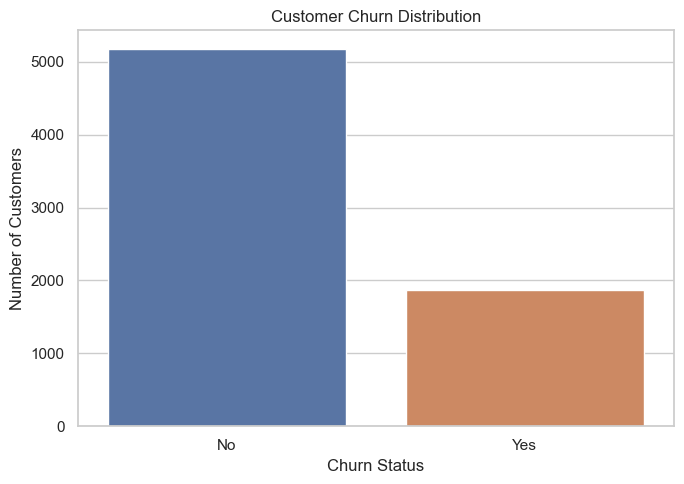

Churn percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [10]:
plt.figure(figsize=(7, 5))
sns.countplot(data=eda, x="Churn", hue="Churn", legend=False)
plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

print("Churn percentage:")
print((eda["Churn"].value_counts(normalize=True) * 100).round(2))

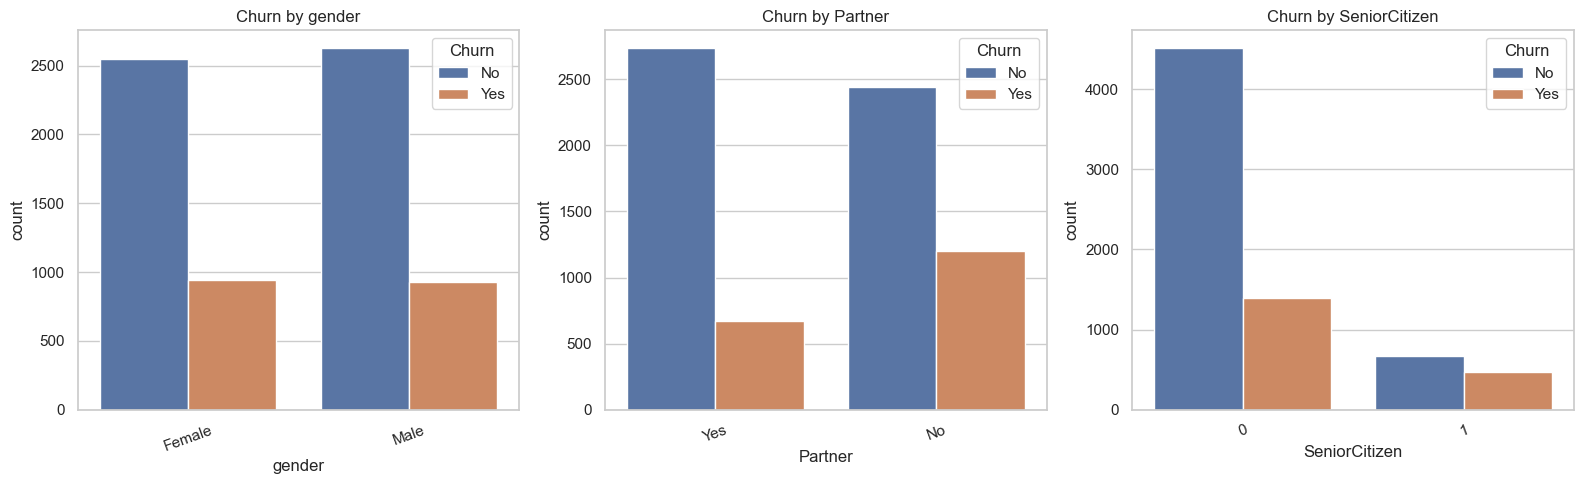

In [11]:
profile_cols = ["gender", "Partner", "SeniorCitizen"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, profile_cols):
    sns.countplot(
        data=eda, x=col, hue="Churn", ax=ax
    )
    ax.set_title(f"Churn by {col}")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

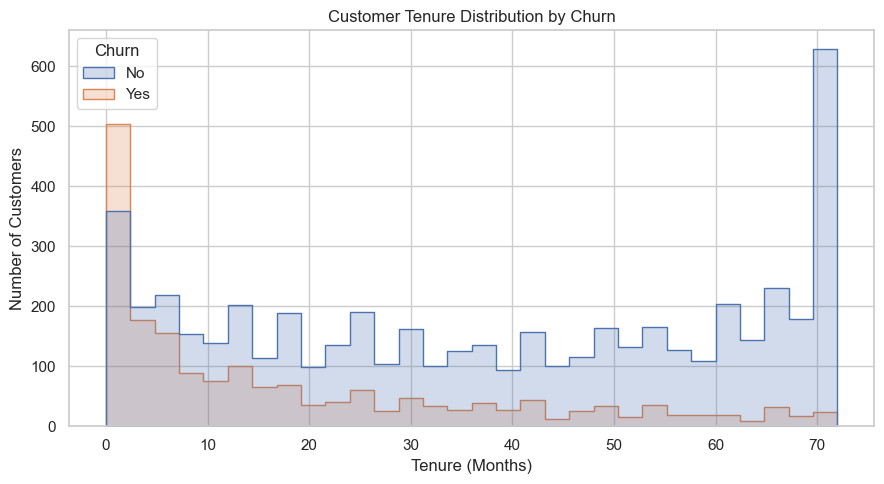

In [12]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=eda, x="tenure", hue="Churn",
    bins=30, multiple="layer", element="step"
)
plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

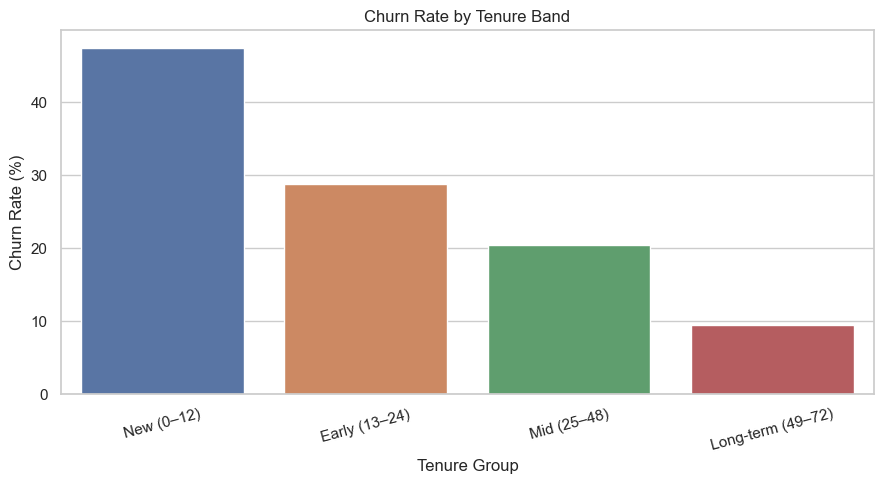

          TenureBand  ChurnRate
0         New (0–12)      47.44
1      Early (13–24)      28.71
2        Mid (25–48)      20.39
3  Long-term (49–72)       9.51


In [15]:
eda["TenureBand"] = pd.cut(
    eda["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["New (0–12)", "Early (13–24)",
            "Mid (25–48)", "Long-term (49–72)"]
)

tenure_churn = (
    eda.groupby("TenureBand", observed=False)["Churn"]
    .apply(lambda s: s.eq("Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

sns.barplot(
    data=tenure_churn, x="TenureBand", y="ChurnRate",
    hue="TenureBand", legend=False
)
plt.title("Churn Rate by Tenure Band")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print(tenure_churn.round(2))

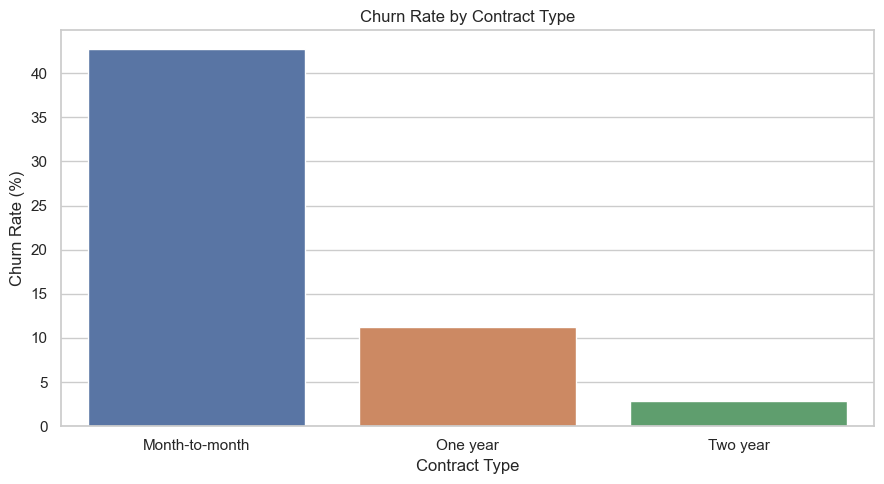

         Contract  ChurnRate
0  Month-to-month      42.71
1        One year      11.27
2        Two year       2.83


In [13]:
contract_churn = (
    eda.groupby("Contract", observed=False)["Churn"]
    .apply(lambda s: s.eq("Yes").mean() * 100)
    .sort_values(ascending=False)
    .reset_index(name="ChurnRate")
)

sns.barplot(
    data=contract_churn, x="Contract", y="ChurnRate",
    hue="Contract", legend=False
)
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

print(contract_churn.round(2))

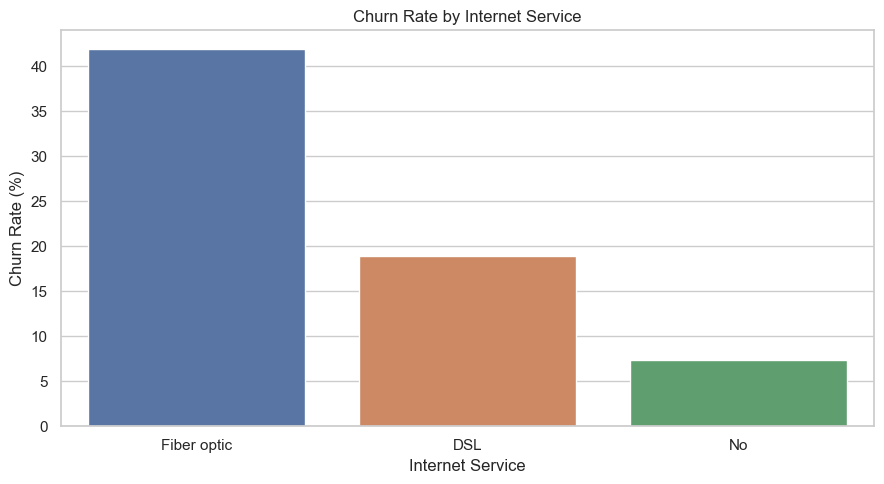

  InternetService  ChurnRate
1     Fiber optic      41.89
0             DSL      18.96
2              No       7.40


In [16]:
service_churn = (
    eda.groupby("InternetService", observed=False)["Churn"]
    .apply(lambda s: s.eq("Yes").mean() * 100)
    .reset_index(name="ChurnRate")
    .sort_values("ChurnRate", ascending=False)
)

sns.barplot(
    data=service_churn, x="InternetService", y="ChurnRate",
    hue="InternetService", legend=False
)
plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

print(service_churn.round(2))

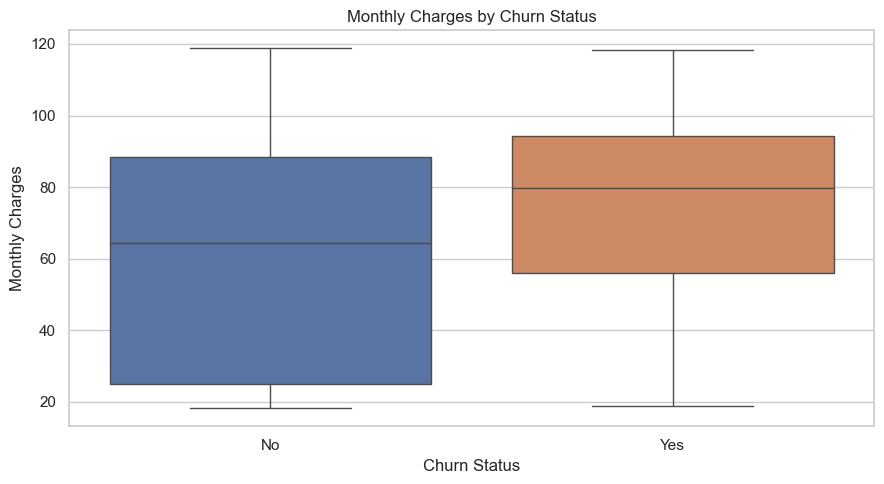

In [17]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=eda, x="Churn", y="MonthlyCharges", hue="Churn",
            legend=False)
plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

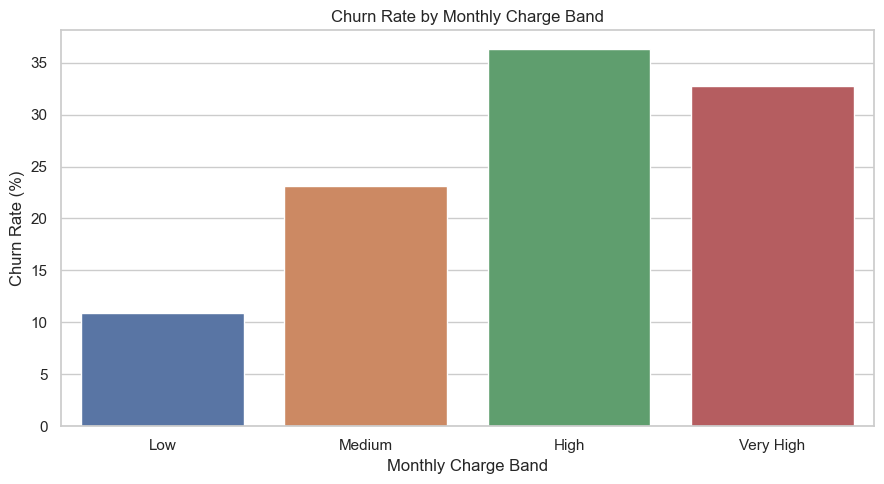

  ChargeBand  ChurnRate
0        Low      10.89
1     Medium      23.14
2       High      36.30
3  Very High      32.78


In [18]:
eda["ChargeBand"] = pd.cut(
    eda["MonthlyCharges"],
    bins=[0, 35, 65, 90, float("inf")],
    labels=["Low", "Medium", "High", "Very High"],
    include_lowest=True
)

charge_churn = (
    eda.groupby("ChargeBand", observed=False)["Churn"]
    .apply(lambda s: s.eq("Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

sns.barplot(
    data=charge_churn, x="ChargeBand", y="ChurnRate",
    hue="ChargeBand", legend=False
)
plt.title("Churn Rate by Monthly Charge Band")
plt.xlabel("Monthly Charge Band")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

print(charge_churn.round(2))

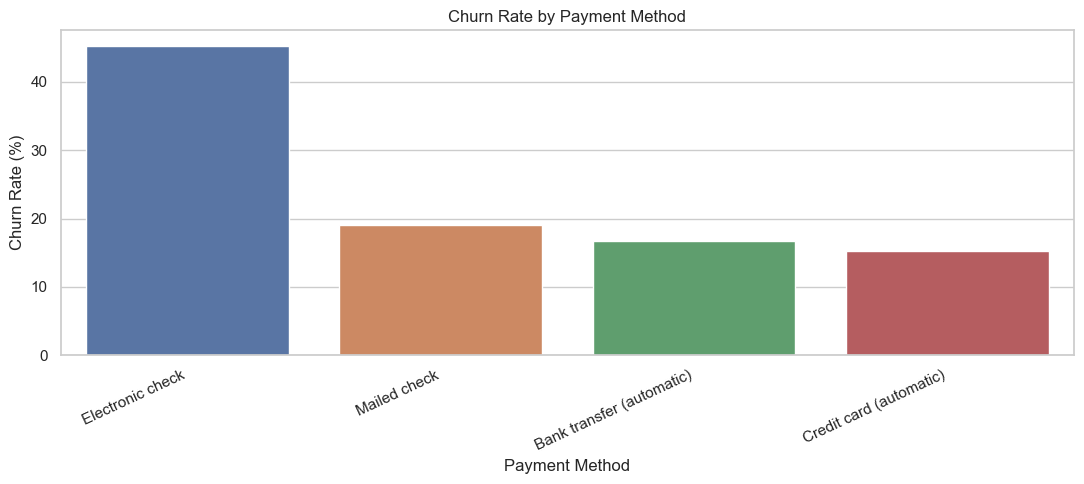

               PaymentMethod  ChurnRate
2           Electronic check      45.29
3               Mailed check      19.11
0  Bank transfer (automatic)      16.71
1    Credit card (automatic)      15.24


In [19]:
payment_churn = (
    eda.groupby("PaymentMethod", observed=False)["Churn"]
    .apply(lambda s: s.eq("Yes").mean() * 100)
    .reset_index(name="ChurnRate")
    .sort_values("ChurnRate", ascending=False)
)

plt.figure(figsize=(11, 5))
sns.barplot(
    data=payment_churn, x="PaymentMethod", y="ChurnRate",
    hue="PaymentMethod", legend=False
)
plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

print(payment_churn.round(2))

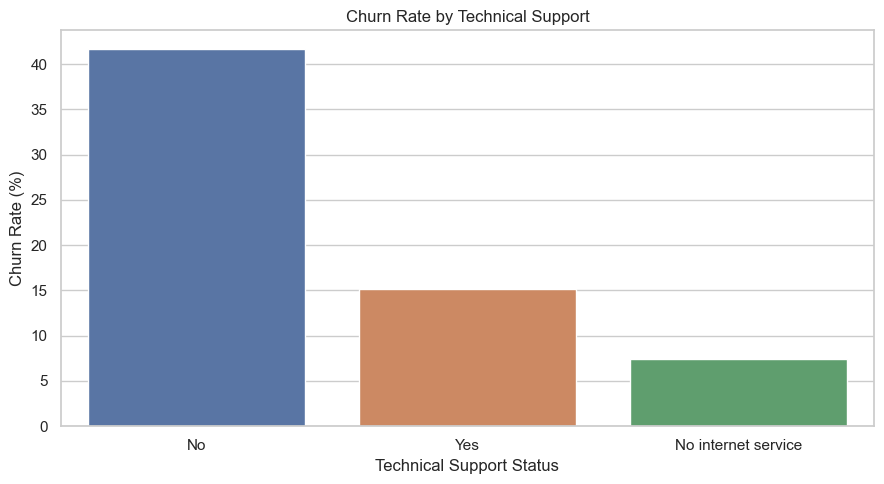

           TechSupport  ChurnRate
0                   No      41.64
2                  Yes      15.17
1  No internet service       7.40


In [20]:
support_churn = (
    eda.groupby("TechSupport", observed=False)["Churn"]
    .apply(lambda s: s.eq("Yes").mean() * 100)
    .reset_index(name="ChurnRate")
    .sort_values("ChurnRate", ascending=False)
)

sns.barplot(
    data=support_churn, x="TechSupport", y="ChurnRate",
    hue="TechSupport", legend=False
)
plt.title("Churn Rate by Technical Support")
plt.xlabel("Technical Support Status")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

print(support_churn.round(2))

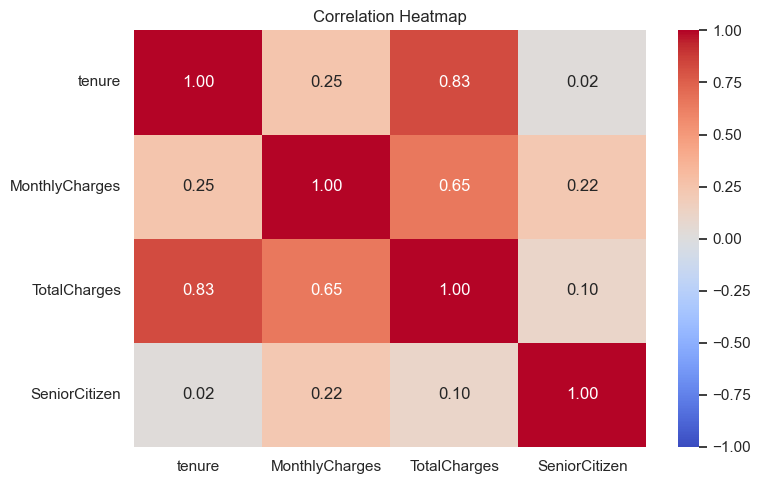

In [21]:
numeric_cols = [
    col for col in
    ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
    if col in eda.columns
]

corr = eda[numeric_cols].corr()

plt.figure(figsize=(8, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm",
            fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

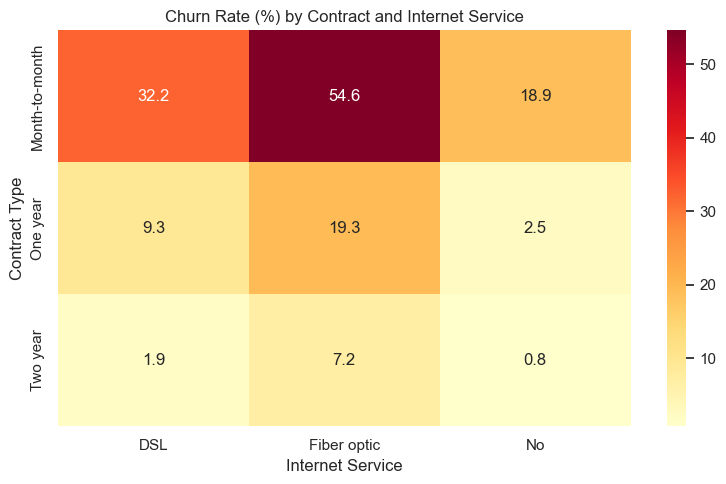

In [22]:
association = pd.crosstab(
    eda["Contract"],
    eda["InternetService"],
    values=eda["Churn"].eq("Yes").astype(int),
    aggfunc="mean"
) * 100

plt.figure(figsize=(8, 5))
sns.heatmap(association, annot=True, fmt=".1f",
            cmap="YlOrRd")
plt.title("Churn Rate (%) by Contract and Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Contract Type")
plt.tight_layout()
plt.show()